In [ ]:
import pandas as pd
from pandas import DataFrame  as df

#데이터 불러오기 시간이랑 트윗 텍스트만
Data = pd.read_csv("청년층이 많이 대출한 책(csv).csv")

Data

In [ ]:
Data.책소개 = Data.책소개.astype(str)

In [ ]:
import pandas as pd
import numpy as np

# 데이터 프레임의 'text' 열의 값들을 str 형식으로 바꾸기
Data['책소개'] = Data['책소개'].astype(str)

# 한글이 아니면 빈 문자열로 바꾸기
Data['책소개'] = Data['책소개'].str.replace('[^ㄱ-ㅎㅏ-ㅣ가-힣]', ' ', regex=True)

# 빈 문자열을 NAN 값으로 바꾸기
Data['책소개'] = Data['책소개'].replace({'': np.nan})
Data['책소개'] = Data['책소개'].replace(r'^\s*$', np.nan, regex=True)

# NAN이 있는 행은 삭제
Data.dropna(subset=['책소개'], how='any', inplace=True)

# 인덱스 차곡차곡
Data = Data.reset_index(drop=True)

# 데이터 프레임에 null 값이 있는지 확인
print(Data.isnull().values.any())


In [ ]:
'''
from konlpy.tag import Okt
import pandas as pd
import numpy as np

# Okt 객체 생성
okt = Okt()

# 텍스트 데이터를 리스트로 변환
Data_list = Data['책소개'].values.tolist()

# 리스트를 요소별로(책소개 하나) 가져와서 명사만 추출한 후 리스트로 저장
data_word = []
for text in Data_list:
    try:
        nouns = okt.nouns(text)
        data_word.append(nouns)
    except Exception as e:
        continue

# 트윗에서 명사만 추출해서 만든 리스트
data_word
'''

In [ ]:
'''
from konlpy.tag import Okt
import pandas as pd
import numpy as np

# Okt 객체 생성
okt = Okt()

# 텍스트 데이터를 리스트로 변환
Data_list = Data['책소개'].values.tolist()

# 리스트를 요소별로(책소개 하나) 가져와서 명사만 추출한 후 리스트로 저장
data_word = []
for text in Data_list:
    try:
        nouns = okt.nouns(text)
        data_word.extend(nouns)  # 명사를 리스트에 추가
    except Exception as e:
        continue

# 중복 제거
data_word = list(set(data_word))

data_word
'''

In [ ]:
from konlpy.tag import Okt
import pandas as pd
import numpy as np

# Okt 객체 생성
okt = Okt()

# 텍스트 데이터를 리스트로 변환
Data_list = Data['책소개'].values.tolist()

# 리스트를 요소별로(책소개 하나) 가져와서 명사만 추출한 후 리스트로 저장
data_word = []
for text in Data_list:
    try:
        nouns = okt.nouns(text)
        # 길이가 2 이상인 명사만 추가
        data_word.extend([noun for noun in nouns if len(noun) > 1])
    except Exception as e:
        continue

# 중복 제거
data_word = list(set(data_word))

# 결과를 데이터프레임으로 변환
nouns_df = pd.DataFrame(data_word, columns=['명사'])

# 데이터프레임 출력
print(nouns_df)

In [ ]:
import pandas as pd
import gensim
import re

# LDA 모델 생성
num_topics = 10  # 토픽 개수 설정
lda_model = gensim.models.LdaModel(corpus, num_topics=num_topics, id2word=id2word, passes=25, random_state=42)

# 결과를 데이터프레임으로 변환
topics = []
for idx, topic in lda_model.print_topics(-1):
    topics.append((idx, topic))

# 데이터프레임 생성
topics_df = pd.DataFrame(topics, columns=['토픽 번호', '주요 단어'])

# 숫자 제거 함수
def remove_numbers(text):
    return re.sub(r'\d+\s*', '', text)

# 주요 단어에서 숫자 제거
topics_df['주요 단어'] = topics_df['주요 단어'].apply(remove_numbers)

# 데이터프레임 출력
print(topics_df)

In [16]:
from konlpy.tag import Okt
import pandas as pd
import numpy as np
import gensim
import re
from gensim.corpora import Dictionary

# Okt 객체 생성
okt = Okt()

# 텍스트 데이터를 리스트로 변환
Data_list = Data['책소개'].values.tolist()

# 리스트를 요소별로(책소개 하나) 가져와서 명사만 추출한 후 리스트로 저장
data_word = []
for text in Data_list:
    try:
        nouns = okt.nouns(text)
        # 길이가 2 이상인 명사만 추가
        data_word.extend([noun for noun in nouns if len(noun) > 1])
    except Exception as e:
        continue

# 중복 제거
data_word = list(set(data_word))

# 결과를 데이터프레임으로 변환
nouns_df = pd.DataFrame(data_word, columns=['명사'])

# 데이터프레임 출력
print(nouns_df)

# LDA 모델 생성
# 명사 리스트를 문서 형태로 변환
documents = [data_word]  # 각 문서에 대해 명사 리스트를 사용

# 사전 생성
id2word = Dictionary(documents)

# 코퍼스 생성
corpus = [id2word.doc2bow(doc) for doc in documents]

# LDA 모델 설정
num_topics = 10  # 토픽 개수 설정
lda_model = gensim.models.LdaModel(corpus, num_topics=num_topics, id2word=id2word, passes=25, random_state=42)

# 결과를 데이터프레임으로 변환
topics = []
for idx, topic in lda_model.print_topics(-1):
    # 주요 단어를 쉼표로 구분하여 저장
    topic_words = topic.split(" + ")
    topic_words = [word.split("*")[1].strip().replace('"', '') for word in topic_words]
    topics.append((idx, ", ".join(topic_words)))

# 데이터프레임 생성
topics_df = pd.DataFrame(topics, columns=['토픽 번호', '주요 단어'])

# 데이터프레임 출력 
print(topics_df)

       명사
0     판가름
1      물성
2      파편
3     어머니
4      한번
...   ...
1895   휴식
1896   씨발
1897   탐욕
1898   레프
1899   여름

[1900 rows x 1 columns]
   토픽 번호                                        주요 단어
0      0     고스, 초점, 전무후무, 순간, 산다, 절망, 근심, 기준, 거치, 재능
1      1     수년, 구체, 잠깐, 프로, 가슴, 쿠키, 홍수, 경우, 체계, 주렁주렁
2      2    마치, 결과물, 나헌, 그날, 암석, 사무실, 부상, 거리, 모욕, 반드시
3      3  큰소리, 최후, 가수, 게다가, 오토바이, 시초, 정기회, 전만, 그게, 태몽
4      4      이기, 시대, 손목, 전가, 청소, 연구, 태위, 그리움, 미동, 수술
5      5       상속, 모이, 의미, 복종, 한계, 파괴, 영업, 서구, 지시, 진지
6      6       카페, 다만, 지폐, 특성, 그때, 꼬박, 상황, 마켓, 정체, 대학
7      7       년도, 순리, 풋내, 나중, 의미, 의심, 열풍, 근성, 주식, 데일
8      8       실재, 필요, 보고, 당시, 구트, 비야, 왕따, 해석, 코너, 사탕
9      9      지나, 오염, 퇴근, 아예, 분실, 주로, 현대, 신의, 편지, 종이컵


In [17]:
font = 'DoHyeon-Regular.ttf'

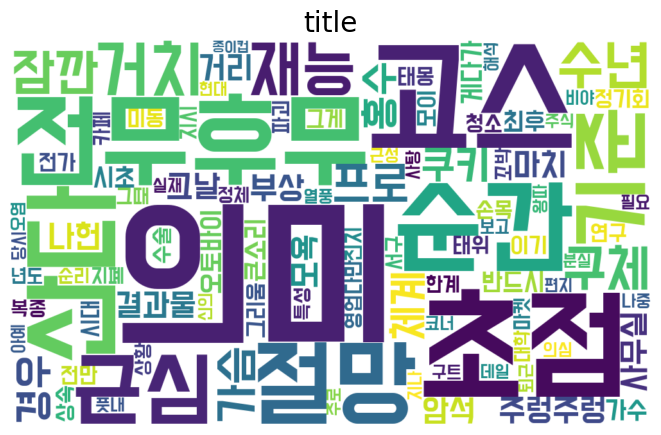

In [18]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# 주요 단어를 문자열로 변환 (예: '단어1, 단어2, 단어3')
word_string = ", ".join(topics_df['주요 단어'].tolist())

# 워드클라우드 생성
wordcloud = WordCloud(
    font_path= font,  # 한글 폰트 경로
    width=1000,
    height=600,
    background_color='white',
    colormap='viridis',  # 색상 맵 설정
    max_words=200,  # 최대 단어 수
    random_state=42  # 랜덤 상태 설정
).generate(word_string)

# 워드클라우드 시각화
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')  # 축 제거
plt.title('title', fontsize=20)
plt.show()